# Course 602 - Data Analytics using Python
## Credit Card Fraud Detection - Complete Project (All 13 Tasks)
### Dataset: Credit Card Fraud | 10,000 Records x 13 Features

---
## Task 1: Data Understanding

In [1]:
# Import all required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import (mean_squared_error, mean_absolute_error,
                              r2_score, accuracy_score, confusion_matrix,
                              classification_report)
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PolynomialFeatures
from scipy.stats import norm, probplot
import warnings
warnings.filterwarnings('ignore')

plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("husl")
print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
# Load the dataset
df = pd.read_csv('credit_card_fraud.csv')
print(f"Shape: {df.shape[0]} rows x {df.shape[1]} columns")
print(f"Memory: {df.memory_usage(deep=True).sum() / 1024:.1f} KB")

Shape: 10000 rows x 13 columns
Memory: 4003.7 KB


In [3]:
# First 5 rows
print("FIRST 5 ROWS:")
df.head()

FIRST 5 ROWS:


,transaction_id,transaction_time,card_type,merchant_category,merchant_location,transaction_amount,transaction_mode,customer_age,customer_gender,account_balance,is_international,failed_attempts,is_fraud
0,1,13:47,Credit,Travel,India,6516.96,Online,27,M,4013.83,Yes,2,1
1,2,08:50,Debit,Groceries,California,3733.66,Online,54,M,NaN,Yes,0,0
2,3,14:28,Credit,Jewelry,China,6892.34,NaN,55,M,348.83,Yes,0,0
3,4,06:55,Credit,Travel,New York,2396.40,Tap,39,M,22058.66,No,4,0
4,5,14:09,Credit,Clothing,China,1830.27,Online,55,F,NaN,No,5,0


In [4]:
# Last 5 rows
print("LAST 5 ROWS:")
df.tail()

LAST 5 ROWS:


,transaction_id,transaction_time,card_type,merchant_category,merchant_location,transaction_amount,transaction_mode,customer_age,customer_gender,account_balance,is_international,failed_attempts,is_fraud
9995,9996,09:05,Credit,Restaurant,New York,6189.84,Swipe,66,M,NaN,Yes,2,1
9996,9997,09:09,Debit,Healthcare,Florida,5834.52,Online,24,NaN,18374.84,No,2,0
9997,9998,05:48,Credit,Fuel,New York,1971.21,Swipe,61,M,8738.11,Yes,5,0
9998,9999,00:02,Credit,Jewelry,New York,3500.68,Swipe,62,F,4722.22,Yes,3,1
9999,10000,16:06,Debit,Travel,Russia,6702.41,NaN,69,M,18307.30,No,2,0


In [5]:
# Column names and data types
print("COLUMN NAMES & DATA TYPES:")
for i, (col, dtype) in enumerate(zip(df.columns, df.dtypes), 1):
    print(f"  {i:2}. {col:<25} -> {str(dtype)}")
print(f"\nDataset Shape: {df.shape}")

COLUMN NAMES & DATA TYPES:
   1. transaction_id            -> int64
   2. transaction_time          -> object
   3. card_type                 -> object
   4. merchant_category         -> object
   5. merchant_location         -> object
   6. transaction_amount        -> float64
   7. transaction_mode          -> object
   8. customer_age              -> int64
   9. customer_gender           -> object
  10. account_balance           -> float64
  11. is_international          -> object
  12. failed_attempts           -> int64
  13. is_fraud                  -> int64

Dataset Shape: (10000, 13)


In [6]:
# Identify Quantitative and Qualitative columns
print("DATA CLASSIFICATION")
print("QUANTITATIVE DATA:")
print("  Continuous : transaction_amount, account_balance, customer_age")
print("  Discrete   : transaction_id, failed_attempts, is_fraud")
print(" ")
print("QUALITATIVE DATA:")
print("  Nominal    : card_type, merchant_category, merchant_location,")
print("               transaction_mode, customer_gender, is_international")
print("  Ordinal    : transaction_time")

DATA CLASSIFICATION
QUANTITATIVE DATA:
  Continuous : transaction_amount, account_balance, customer_age
  Discrete   : transaction_id, failed_attempts, is_fraud
 
QUALITATIVE DATA:
  Nominal    : card_type, merchant_category, merchant_location,
               transaction_mode, customer_gender, is_international
  Ordinal    : transaction_time


---
## Task 2: Exploratory Data Analysis (EDA)
### 2A - Univariate Analysis

In [7]:
# Fix inconsistent casing in transaction_mode
df['transaction_mode'] = df['transaction_mode'].str.strip().str.title()
print("Unique transaction modes:", df['transaction_mode'].value_counts().to_dict())

Unique transaction modes: {'Swipe': 2598, 'Tap': 2458, 'Online': 2452}


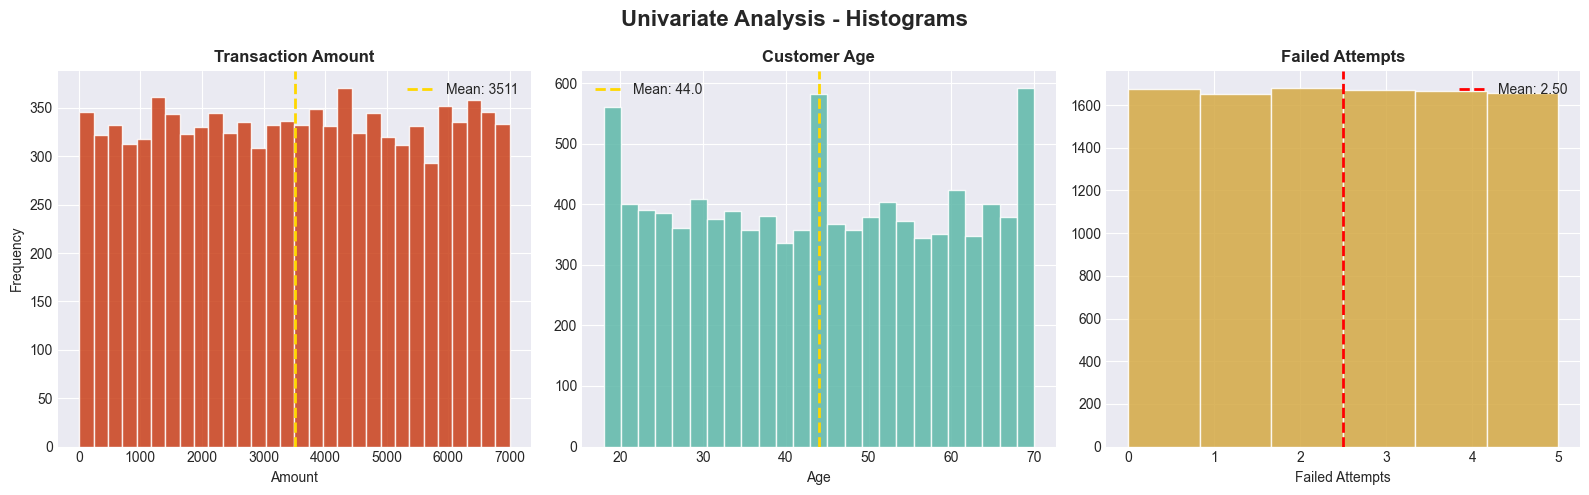

In [8]:
# Univariate - Histograms
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
fig.suptitle("Univariate Analysis - Histograms", fontsize=16, fontweight='bold')

axes[0].hist(df['transaction_amount'], bins=30, color='#C9401A', edgecolor='white', alpha=0.85)
axes[0].set_title('Transaction Amount', fontweight='bold')
axes[0].set_xlabel('Amount')
axes[0].set_ylabel('Frequency')
axes[0].axvline(df['transaction_amount'].mean(), color='gold', linestyle='--', linewidth=2,
               label=f"Mean: {df['transaction_amount'].mean():.0f}")
axes[0].legend()

axes[1].hist(df['customer_age'], bins=25, color='#5DB8A8', edgecolor='white', alpha=0.85)
axes[1].set_title('Customer Age', fontweight='bold')
axes[1].set_xlabel('Age')
axes[1].axvline(df['customer_age'].mean(), color='gold', linestyle='--', linewidth=2,
               label=f"Mean: {df['customer_age'].mean():.1f}")
axes[1].legend()

axes[2].hist(df['failed_attempts'], bins=6, color='#D4A843', edgecolor='white', alpha=0.85)
axes[2].set_title('Failed Attempts', fontweight='bold')
axes[2].set_xlabel('Failed Attempts')
axes[2].axvline(df['failed_attempts'].mean(), color='red', linestyle='--', linewidth=2,
               label=f"Mean: {df['failed_attempts'].mean():.2f}")
axes[2].legend()

plt.tight_layout()
plt.savefig('task2_histograms.png', dpi=150, bbox_inches='tight')
plt.show()

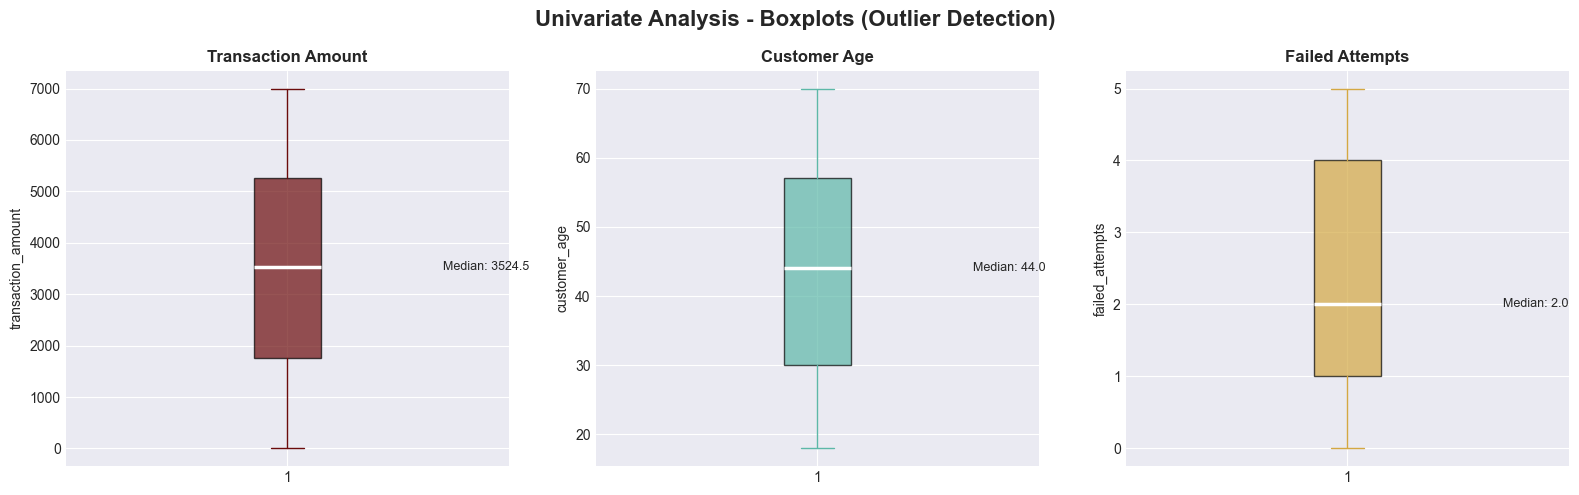

In [9]:
# Univariate - Boxplots
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
fig.suptitle("Univariate Analysis - Boxplots (Outlier Detection)", fontsize=16, fontweight='bold')

cols_box = ['transaction_amount', 'customer_age', 'failed_attempts']
colors_box = ['#6B0B0C', '#5DB8A8', '#D4A843']
titles_box = ['Transaction Amount', 'Customer Age', 'Failed Attempts']

for ax, col, title, color in zip(axes, cols_box, titles_box, colors_box):
    bp = ax.boxplot(df[col].dropna(), patch_artist=True,
                    boxprops=dict(facecolor=color, alpha=0.7),
                    medianprops=dict(color='white', linewidth=2.5),
                    whiskerprops=dict(color=color),
                    capprops=dict(color=color),
                    flierprops=dict(marker='o', color=color, alpha=0.4, markersize=4))
    ax.set_title(title, fontweight='bold')
    ax.set_ylabel(col)
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    ax.text(1.35, df[col].median(), f'Median: {df[col].median():.1f}', va='center', fontsize=9)

plt.tight_layout()
plt.savefig('task2_boxplots.png', dpi=150, bbox_inches='tight')
plt.show()

### 2B - Bivariate Analysis

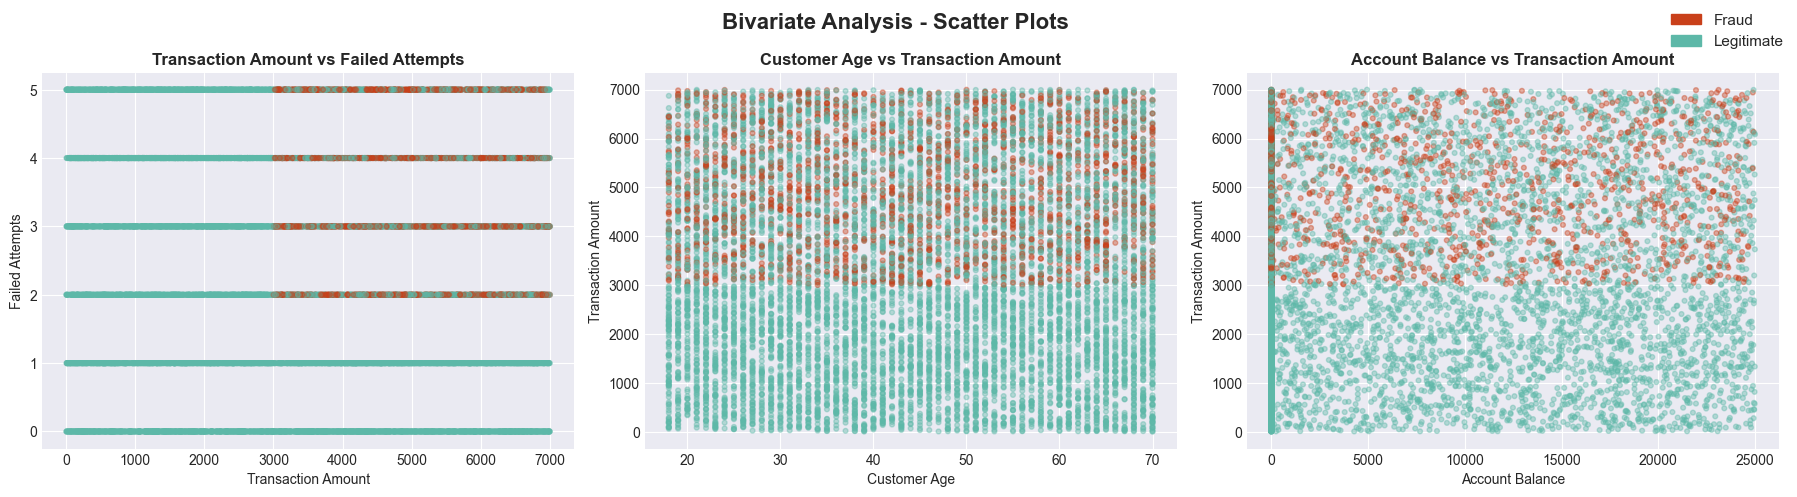

In [ ]:
# Bivariate - Scatter Plots
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle("Bivariate Analysis - Scatter Plots", fontsize=16, fontweight='bold')

colors_map = df['is_fraud'].map({0: '#5DB8A8', 1: '#C9401A'})

axes[0].scatter(df['transaction_amount'], df['failed_attempts'],
                c=colors_map, alpha=0.4, s=12)
axes[0].set_title('Transaction Amount vs Failed Attempts', fontweight='bold')
axes[0].set_xlabel('Transaction Amount')
axes[0].set_ylabel('Failed Attempts')

axes[1].scatter(df['customer_age'], df['transaction_amount'],
                c=colors_map, alpha=0.4, s=12)
axes[1].set_title('Customer Age vs Transaction Amount', fontweight='bold')
axes[1].set_xlabel('Customer Age')
axes[1].set_ylabel('Transaction Amount')

axes[2].scatter(df['account_balance'].fillna(0), df['transaction_amount'],
                c=colors_map, alpha=0.4, s=12)
axes[2].set_title('Account Balance vs Transaction Amount', fontweight='bold')
axes[2].set_xlabel('Account Balance')
axes[2].set_ylabel('Transaction Amount')

fraud_patch = mpatches.Patch(color='#C9401A', label='Fraud')
legit_patch = mpatches.Patch(color='#5DB8A8', label='Legitimate')
fig.legend(handles=[fraud_patch, legit_patch], loc='upper right', fontsize=11)
plt.tight_layout()
plt.savefig('task2_scatter.png', dpi=150, bbox_inches='tight')
plt.show()

### 2C - Multivariate Analysis

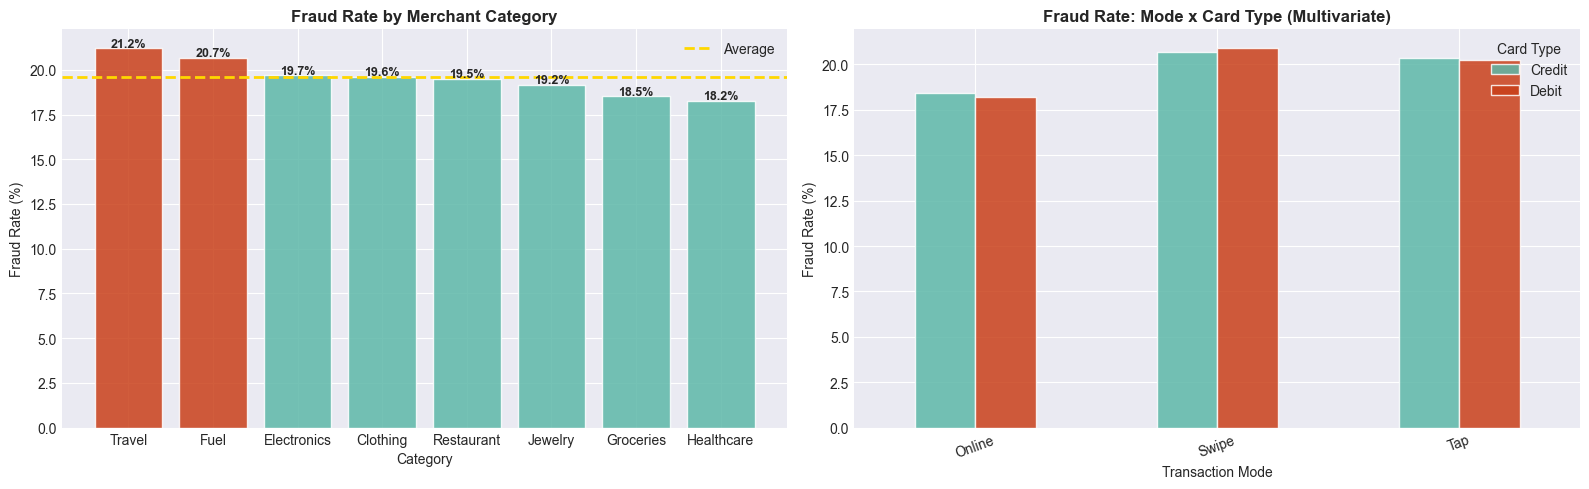

In [11]:
# Multivariate - Fraud rate across categories
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Merchant Category
fraud_cat = df.groupby('merchant_category')['is_fraud'].mean().sort_values(ascending=False) * 100
axes[0].bar(fraud_cat.index, fraud_cat.values,
            color=['#C9401A' if v>20 else '#5DB8A8' for v in fraud_cat.values],
            edgecolor='white', alpha=0.85)
axes[0].set_title('Fraud Rate by Merchant Category', fontweight='bold')
axes[0].set_xlabel('Category')
axes[0].set_ylabel('Fraud Rate (%)')
axes[0].axhline(fraud_cat.mean(), color='gold', linestyle='--', linewidth=2, label='Average')
axes[0].legend()
for i, v in enumerate(fraud_cat.values):
    axes[0].text(i, v+0.1, f'{v:.1f}%', ha='center', fontsize=9, fontweight='bold')

# Transaction mode vs card type (grouped)
pivot = df.groupby(['transaction_mode','card_type'])['is_fraud'].mean().unstack() * 100
pivot.plot(kind='bar', ax=axes[1], color=['#5DB8A8','#C9401A'], edgecolor='white', alpha=0.85)
axes[1].set_title('Fraud Rate: Mode x Card Type (Multivariate)', fontweight='bold')
axes[1].set_xlabel('Transaction Mode')
axes[1].set_ylabel('Fraud Rate (%)')
axes[1].legend(title='Card Type')
axes[1].tick_params(axis='x', rotation=20)

plt.tight_layout()
plt.savefig('task2_multivariate.png', dpi=150, bbox_inches='tight')
plt.show()

---
## Task 3: Handling Missing Data and Outliers

In [12]:
# Step 1 - Identify Missing Values
print("MISSING VALUE ANALYSIS")
missing = df.isnull().sum()
missing_pct = (df.isnull().sum() / len(df)) * 100
missing_df = pd.DataFrame({'Missing Count': missing, 'Missing %': missing_pct.round(2)})
print(missing_df[missing_df['Missing Count'] > 0].sort_values('Missing Count', ascending=False))
print(f"Columns with NO missing values: {(missing == 0).sum()}")

MISSING VALUE ANALYSIS
                   Missing Count  Missing %
account_balance             5022      50.22
customer_gender             3333      33.33
transaction_mode            2492      24.92
merchant_location            945       9.45
Columns with NO missing values: 9


In [13]:
# Step 2 - Handle Missing Values
df['account_balance'].fillna(df['account_balance'].median(), inplace=True)  # Continuous -> Median
df['customer_gender'].fillna(df['customer_gender'].mode()[0], inplace=True)  # Nominal -> Mode
df['transaction_mode'].fillna(df['transaction_mode'].mode()[0], inplace=True)  # Nominal -> Mode
df['merchant_location'].fillna('Unknown', inplace=True)  # Too many -> Unknown label

print("AFTER IMPUTATION - Remaining Missing Values:")
remaining = df.isnull().sum()
print(remaining[remaining > 0] if remaining.sum() > 0 else "Zero missing values! All handled.")

AFTER IMPUTATION - Remaining Missing Values:
Zero missing values! All handled.


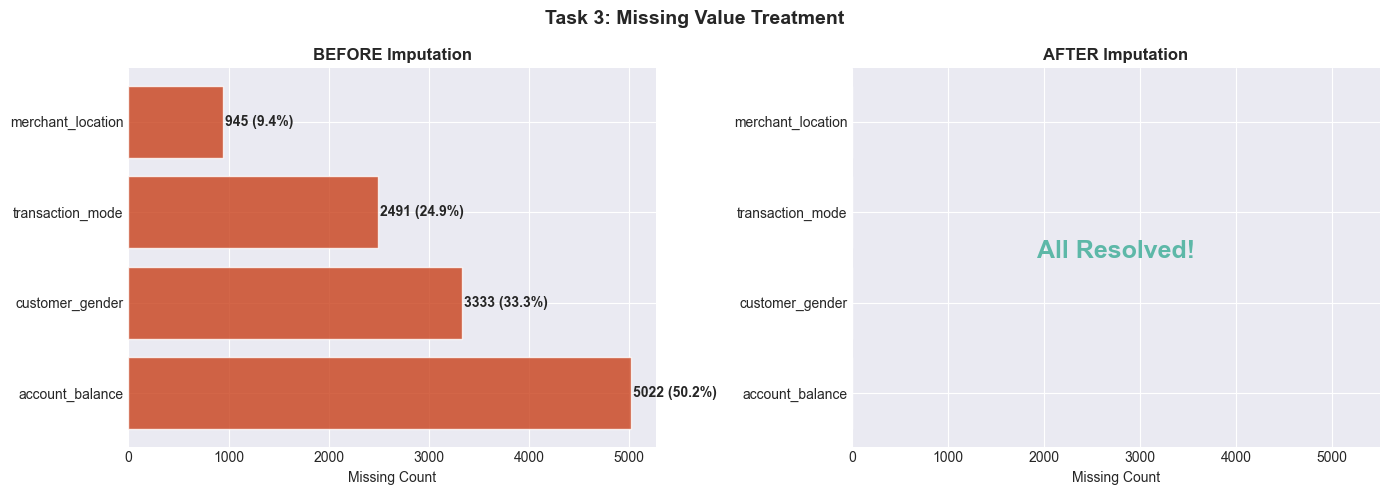

In [14]:
# Step 3 - Visualize Missing Values
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Task 3: Missing Value Treatment', fontsize=14, fontweight='bold')

cols_miss = ['account_balance', 'customer_gender', 'transaction_mode', 'merchant_location']
counts_before = [5022, 3333, 2491, 945]

axes[0].barh(cols_miss, counts_before, color='#C9401A', alpha=0.8, edgecolor='white')
axes[0].set_title('BEFORE Imputation', fontweight='bold')
axes[0].set_xlabel('Missing Count')
for i, v in enumerate(counts_before):
    axes[0].text(v+20, i, f'{v} ({v/10000*100:.1f}%)', va='center', fontweight='bold', fontsize=10)

axes[1].barh(cols_miss, [0,0,0,0], color='#5DB8A8', alpha=0.8, edgecolor='white')
axes[1].set_title('AFTER Imputation', fontweight='bold')
axes[1].set_xlabel('Missing Count')
axes[1].set_xlim(0, 5500)
axes[1].text(2750, 1.5, 'All Resolved!', ha='center', fontsize=18, color='#5DB8A8', fontweight='bold')

plt.tight_layout()
plt.savefig('task3_missing.png', dpi=150, bbox_inches='tight')
plt.show()

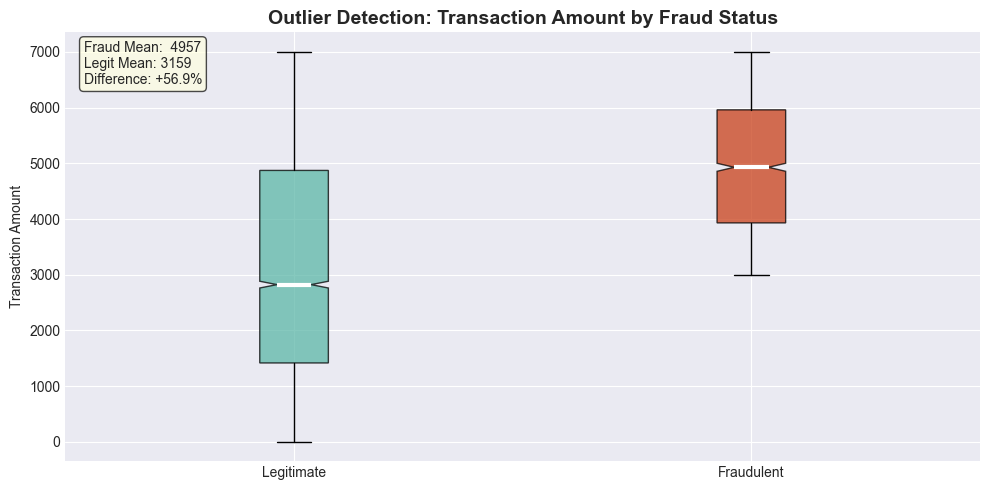

Impact: Fraud transactions are 56.9% higher in amount than legitimate ones.


In [15]:
# Step 4 - Outlier Detection using Boxplot
fig, ax = plt.subplots(figsize=(10, 5))
fraud_amt = df[df['is_fraud']==1]['transaction_amount']
legit_amt = df[df['is_fraud']==0]['transaction_amount']

bp = ax.boxplot([legit_amt, fraud_amt], patch_artist=True, notch=True,
                labels=['Legitimate', 'Fraudulent'],
                medianprops=dict(color='white', linewidth=3))
bp['boxes'][0].set_facecolor('#5DB8A8'); bp['boxes'][0].set_alpha(0.75)
bp['boxes'][1].set_facecolor('#C9401A'); bp['boxes'][1].set_alpha(0.75)

ax.set_title('Outlier Detection: Transaction Amount by Fraud Status', fontsize=14, fontweight='bold')
ax.set_ylabel('Transaction Amount')
info_txt = (f"Fraud Mean:  {fraud_amt.mean():.0f}\n"
            f"Legit Mean: {legit_amt.mean():.0f}\n"
            f"Difference: +{((fraud_amt.mean()/legit_amt.mean()-1)*100):.1f}%")
ax.text(0.02, 0.98, info_txt, transform=ax.transAxes, va='top', fontsize=10,
        bbox=dict(boxstyle='round', facecolor='lightyellow', alpha=0.7))
plt.tight_layout()
plt.savefig('task3_outliers.png', dpi=150, bbox_inches='tight')
plt.show()
print(f"Impact: Fraud transactions are {((fraud_amt.mean()/legit_amt.mean()-1)*100):.1f}% higher in amount than legitimate ones.")

---
## Task 4: Spread of Data

In [16]:
# Statistical Moments
amt = df['transaction_amount']
print("STATISTICAL ANALYSIS - TRANSACTION AMOUNT")
print("="*50)
stats = {
    'Mean':              amt.mean(),
    'Median':            amt.median(),
    'Std Deviation':     amt.std(),
    'Variance':          amt.var(),
    'Skewness':          amt.skew(),
    'Kurtosis':          amt.kurtosis(),
    'Min':               amt.min(),
    'Max':               amt.max(),
    'Q1 (25%)':          amt.quantile(0.25),
    'Q3 (75%)':          amt.quantile(0.75),
    'IQR':               amt.quantile(0.75) - amt.quantile(0.25)
}
for k, v in stats.items():
    print(f"  {k:<20}: {v:>12,.4f}")

print(f"\nINTERPRETATION:")
print(f"  Skewness = {amt.skew():.4f} -> Near-symmetric (|skew| < 0.5 = approximately normal)")
print(f"  Kurtosis = {amt.kurtosis():.4f} -> Platykurtic (flatter than normal distribution)")

STATISTICAL ANALYSIS - TRANSACTION AMOUNT
  Mean                :   3,511.1416
  Median              :   3,524.5000
  Std Deviation       :   2,021.7278
  Variance            : 4,087,383.4280
  Skewness            :      -0.0015
  Kurtosis            :      -1.1964
  Min                 :       5.8800
  Max                 :   6,999.1200
  Q1 (25%)            :   1,754.0725
  Q3 (75%)            :   5,265.6525
  IQR                 :   3,511.5800

INTERPRETATION:
  Skewness = -0.0015 -> Near-symmetric (|skew| < 0.5 = approximately normal)
  Kurtosis = -1.1964 -> Platykurtic (flatter than normal distribution)


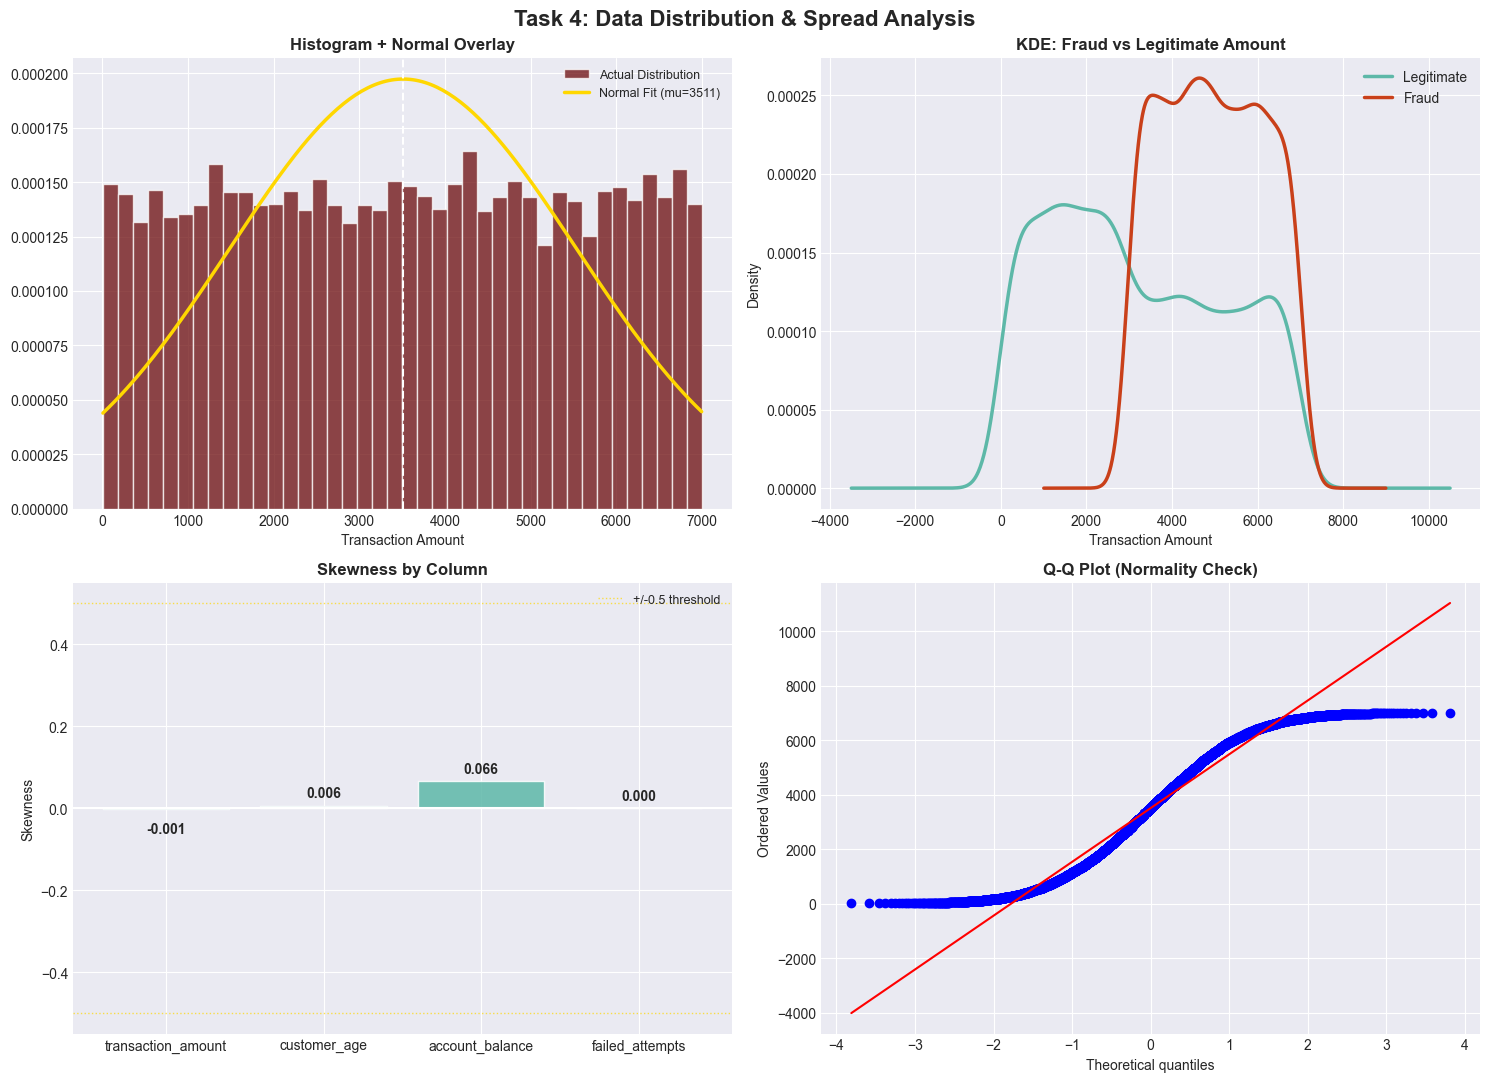

In [17]:
# Distribution Plots
fig, axes = plt.subplots(2, 2, figsize=(15, 11))
fig.suptitle('Task 4: Data Distribution & Spread Analysis', fontsize=16, fontweight='bold')
amt = df['transaction_amount']

# 1. Histogram + Normal Curve
axes[0,0].hist(amt, bins=40, density=True, color='#6B0B0C', alpha=0.75, edgecolor='white', label='Actual Distribution')
mu, sigma = amt.mean(), amt.std()
x = np.linspace(amt.min(), amt.max(), 200)
axes[0,0].plot(x, norm.pdf(x, mu, sigma), 'gold', linewidth=2.5, label=f'Normal Fit (mu={mu:.0f})')
axes[0,0].axvline(mu, color='white', linestyle='--', linewidth=1.5)
axes[0,0].set_title('Histogram + Normal Overlay', fontweight='bold')
axes[0,0].set_xlabel('Transaction Amount')
axes[0,0].legend(fontsize=9)

# 2. KDE - Fraud vs Legit
df[df['is_fraud']==0]['transaction_amount'].plot.kde(ax=axes[0,1], color='#5DB8A8', linewidth=2.5, label='Legitimate')
df[df['is_fraud']==1]['transaction_amount'].plot.kde(ax=axes[0,1], color='#C9401A', linewidth=2.5, label='Fraud')
axes[0,1].set_title('KDE: Fraud vs Legitimate Amount', fontweight='bold')
axes[0,1].set_xlabel('Transaction Amount')
axes[0,1].legend()

# 3. Skewness comparison
num_cols_sk = ['transaction_amount','customer_age','account_balance','failed_attempts']
skews = [df[c].skew() for c in num_cols_sk]
bar_c = ['#C9401A' if abs(s)>0.5 else '#5DB8A8' for s in skews]
axes[1,0].bar(num_cols_sk, skews, color=bar_c, edgecolor='white', alpha=0.85)
axes[1,0].axhline(0, color='white', linewidth=1.5)
axes[1,0].axhline(0.5,  color='gold', linewidth=1, linestyle=':', alpha=0.7, label='+/-0.5 threshold')
axes[1,0].axhline(-0.5, color='gold', linewidth=1, linestyle=':', alpha=0.7)
axes[1,0].set_title('Skewness by Column', fontweight='bold')
axes[1,0].set_ylabel('Skewness')
axes[1,0].legend(fontsize=9)
for i, v in enumerate(skews):
    axes[1,0].text(i, v + (0.02 if v >= 0 else -0.06), f'{v:.3f}', ha='center', fontsize=10, fontweight='bold')

# 4. Q-Q Plot
probplot(amt, dist="norm", plot=axes[1,1])
axes[1,1].set_title('Q-Q Plot (Normality Check)', fontweight='bold')

plt.tight_layout()
plt.savefig('task4_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

---
## Task 5: Automating EDA using Python

In [18]:
# Reusable EDA Functions
def eda_summary(dataframe):
    """Automated EDA summary - combines describe(), info(), isnull(), corr()"""
    print("\n" + "="*55)
    print("  AUTOMATED EDA REPORT")
    print("="*55)
    print(f"  Shape  : {dataframe.shape[0]} rows x {dataframe.shape[1]} columns")
    print(f"  Nulls  : {dataframe.isnull().sum().sum()} total missing values")
    print(f"  Dupes  : {dataframe.duplicated().sum()} duplicate rows\n")
    print("--- info() output ---")
    dataframe.info()
    return dataframe.describe(include='all').round(2)

def missing_report(dataframe):
    """isnull() wrapper with percentage"""
    m = dataframe.isnull().sum()
    return pd.DataFrame({'Count': m, 'Pct': (m/len(dataframe)*100).round(2)})[m > 0]

def correlation_heatmap(dataframe):
    """corr() wrapper with visualization"""
    num_df = dataframe.select_dtypes(include=[np.number])
    corr = num_df.corr().round(4)
    fig, ax = plt.subplots(figsize=(8, 6))
    sns.heatmap(corr, annot=True, fmt='.3f', cmap='RdYlGn', center=0,
                square=True, linewidths=0.5, ax=ax)
    ax.set_title('Auto-EDA: Correlation Matrix', fontweight='bold')
    plt.tight_layout()
    plt.show()
    return corr

# Run automated EDA
stats_table = eda_summary(df)
stats_table


  AUTOMATED EDA REPORT
  Shape  : 10000 rows x 13 columns
  Nulls  : 0 total missing values
  Dupes  : 0 duplicate rows

--- info() output ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 13 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   transaction_id      10000 non-null  int64  
 1   transaction_time    10000 non-null  object 
 2   card_type           10000 non-null  object 
 3   merchant_category   10000 non-null  object 
 4   merchant_location   10000 non-null  object 
 5   transaction_amount  10000 non-null  float64
 6   transaction_mode    10000 non-null  object 
 7   customer_age        10000 non-null  int64  
 8   customer_gender     10000 non-null  object 
 9   account_balance     10000 non-null  float64
 10  is_international    10000 non-null  object 
 11  failed_attempts     10000 non-null  int64  
 12  is_fraud            10000 non-null  int64  
dtypes: float

,transaction_id,transaction_time,card_type,merchant_category,merchant_location,transaction_amount,transaction_mode,customer_age,customer_gender,account_balance,is_international,failed_attempts,is_fraud
count,10000.00,10000,10000,10000,10000,10000.00,10000,10000.00,10000,10000.00,10000,10000.00,10000.0
unique,NaN,1438,2,8,11,NaN,3,NaN,2,NaN,2,NaN,NaN
top,NaN,11:48,Credit,Healthcare,Unknown,NaN,Swipe,NaN,F,NaN,Yes,NaN,NaN
freq,NaN,16,5045,1277,945,NaN,5090,NaN,6674,NaN,5015,NaN,NaN
mean,5000.50,NaN,NaN,NaN,NaN,3511.14,NaN,43.99,NaN,12358.17,NaN,2.50,0.2
std,2886.90,NaN,NaN,NaN,NaN,2021.73,NaN,15.42,NaN,5087.29,NaN,1.71,0.4
min,1.00,NaN,NaN,NaN,NaN,5.88,NaN,18.00,NaN,106.04,NaN,0.00,0.0
25%,2500.75,NaN,NaN,NaN,NaN,1754.07,NaN,30.00,NaN,12300.16,NaN,1.00,0.0
50%,5000.50,NaN,NaN,NaN,NaN,3524.50,NaN,44.00,NaN,12300.16,NaN,2.00,0.0
75%,7500.25,NaN,NaN,NaN,NaN,5265.65,NaN,57.00,NaN,12300.16,NaN,4.00,0.0


In [19]:
# Auto missing check
print("Missing Values Report (post-imputation):")
missing_report(df)

Missing Values Report (post-imputation):


,Count,Pct


Correlation Matrix:


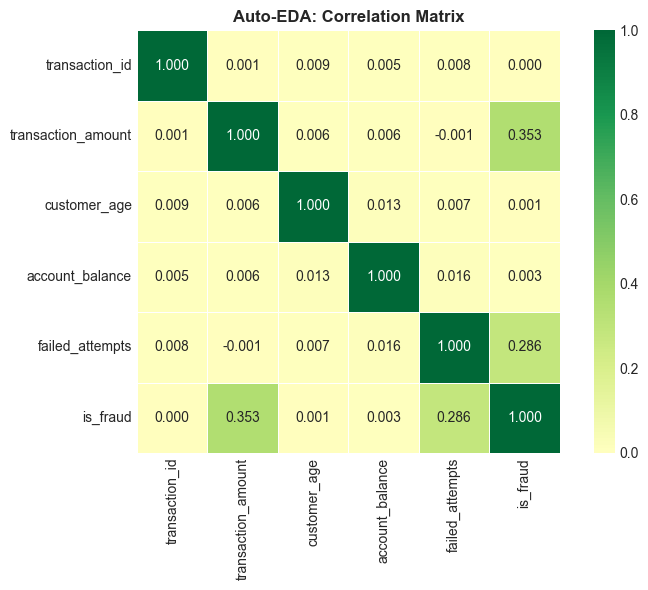

,transaction_id,transaction_amount,customer_age,account_balance,failed_attempts,is_fraud
transaction_id,1.0000,0.0014,0.0095,0.0049,0.0082,0.0003
transaction_amount,0.0014,1.0000,0.0056,0.0062,-0.0013,0.3527
customer_age,0.0095,0.0056,1.0000,0.0130,0.0069,0.0005
account_balance,0.0049,0.0062,0.0130,1.0000,0.0162,0.0028
failed_attempts,0.0082,-0.0013,0.0069,0.0162,1.0000,0.2857
is_fraud,0.0003,0.3527,0.0005,0.0028,0.2857,1.0000


In [20]:
# Auto correlation
print("Correlation Matrix:")
corr = correlation_heatmap(df)
corr

---
## Task 6: Regression Analysis — Covariance & Correlation

In [21]:
# Covariance Matrix
num_cols = ['transaction_amount', 'customer_age', 'account_balance', 'failed_attempts', 'is_fraud']
cov_matrix = df[num_cols].cov().round(2)
print("COVARIANCE MATRIX:")
print(cov_matrix)

COVARIANCE MATRIX:
                    transaction_amount  customer_age  account_balance  \
transaction_amount          4087383.43        175.92         63402.56   
customer_age                    175.92        237.66          1021.69   
account_balance               63402.56       1021.69      25880528.42   
failed_attempts                  -4.57          0.18           140.68   
is_fraud                        282.89          0.00             5.61   

                    failed_attempts  is_fraud  
transaction_amount            -4.57    282.89  
customer_age                   0.18      0.00  
account_balance              140.68      5.61  
failed_attempts                2.91      0.19  
is_fraud                       0.19      0.16  


In [22]:
# Pearson Correlation
corr = df[num_cols].corr().round(4)
print("PEARSON CORRELATION WITH is_fraud:")
fraud_corr = corr['is_fraud'].drop('is_fraud').sort_values(key=abs, ascending=False)
for feat, val in fraud_corr.items():
    bar = 'X' * int(abs(val) * 30)
    print(f"  {feat:<25} {val:+.4f}  |{bar}|")
print("\nFinding: transaction_amount (r=0.35) & failed_attempts (r=0.29) are top predictors")

PEARSON CORRELATION WITH is_fraud:
  transaction_amount        +0.3527  |XXXXXXXXXX|
  failed_attempts           +0.2857  |XXXXXXXX|
  account_balance           +0.0028  ||
  customer_age              +0.0005  ||

Finding: transaction_amount (r=0.35) & failed_attempts (r=0.29) are top predictors


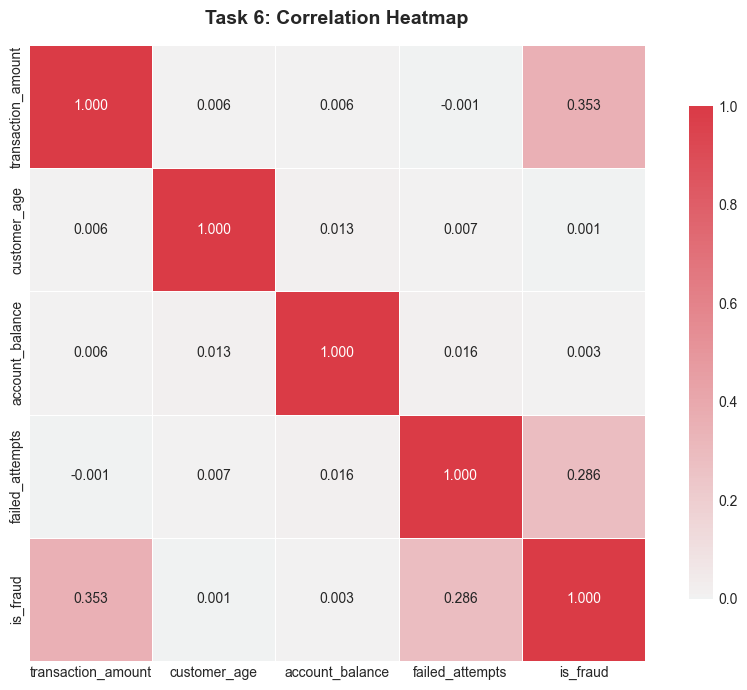

In [23]:
# Correlation Heatmap
fig, ax = plt.subplots(figsize=(9, 7))
cmap = sns.diverging_palette(220, 10, as_cmap=True)
sns.heatmap(corr, annot=True, fmt='.3f', cmap=cmap, center=0,
            square=True, linewidths=0.5, cbar_kws={"shrink": 0.8}, ax=ax)
ax.set_title('Task 6: Correlation Heatmap', fontsize=14, fontweight='bold', pad=15)
plt.tight_layout()
plt.savefig('task6_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()

---
## Task 7: Supervised Learning - Regression Models
### (i) Simple LR  (ii) Multi LR  (iii) Logistic Regression

In [24]:
# Data Preprocessing
df_ml = df.copy()
le = LabelEncoder()
for col in ['card_type','merchant_category','merchant_location',
            'transaction_mode','customer_gender','is_international']:
    df_ml[col] = le.fit_transform(df_ml[col].astype(str))

features = ['transaction_amount','customer_age','account_balance',
            'failed_attempts','card_type','merchant_category',
            'is_international','transaction_mode']
X = df_ml[features]
y = df_ml['is_fraud']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(f"Train: {X_train.shape}  |  Test: {X_test.shape}")
print(f"Train fraud rate: {y_train.mean()*100:.2f}%  |  Test fraud rate: {y_test.mean()*100:.2f}%")

Train: (8000, 8)  |  Test: (2000, 8)
Train fraud rate: 19.49%  |  Test fraud rate: 19.85%


In [25]:
# (i) Simple Linear Regression
X_s_train = X_train[['transaction_amount']]
X_s_test  = X_test[['transaction_amount']]
slr = LinearRegression()
slr.fit(X_s_train, y_train)
y_slr = slr.predict(X_s_test)
mse_slr = mean_squared_error(y_test, y_slr)
mae_slr = mean_absolute_error(y_test, y_slr)
r2_slr  = r2_score(y_test, y_slr)

print("(i) SIMPLE LINEAR REGRESSION")
print(f"  Coefficient : {slr.coef_[0]:.6f}")
print(f"  Intercept   : {slr.intercept_:.6f}")
print(f"  MSE         : {mse_slr:.6f}")
print(f"  MAE         : {mae_slr:.6f}")
print(f"  R2 Score    : {r2_slr:.4f}")

(i) SIMPLE LINEAR REGRESSION
  Coefficient : 0.000069
  Intercept   : -0.047571
  MSE         : 0.139578
  MAE         : 0.282903
  R2 Score    : 0.1227


In [26]:
# (ii) Multi Linear Regression
mlr = LinearRegression()
mlr.fit(X_train, y_train)
y_mlr = mlr.predict(X_test)
mse_mlr = mean_squared_error(y_test, y_mlr)
mae_mlr = mean_absolute_error(y_test, y_mlr)
r2_mlr  = r2_score(y_test, y_mlr)

print("(ii) MULTI LINEAR REGRESSION")
print(f"  Features    : {len(features)}")
print(f"  MSE         : {mse_mlr:.6f}")
print(f"  MAE         : {mae_mlr:.6f}")
print(f"  R2 Score    : {r2_mlr:.4f}")
print(f"  Improvement : +{(r2_mlr - r2_slr)*100:.1f}% R2 vs Simple LR")
print("\nFeature Coefficients (sorted by importance):")
for feat, coef in sorted(zip(features, mlr.coef_), key=lambda x: abs(x[1]), reverse=True):
    print(f"  {feat:<25} : {coef:+.6f}")

(ii) MULTI LINEAR REGRESSION
  Features    : 8
  MSE         : 0.087418
  MAE         : 0.248167
  R2 Score    : 0.4505
  Improvement : +32.8% R2 vs Simple LR

Feature Coefficients (sorted by importance):
  is_international          : +0.387209
  failed_attempts           : +0.065258
  transaction_mode          : +0.006547
  card_type                 : -0.004383
  merchant_category         : +0.000221
  customer_age              : -0.000111
  transaction_amount        : +0.000071
  account_balance           : +0.000000


In [27]:
# (iii) Logistic Regression
scaler = StandardScaler()
Xtr_sc = scaler.fit_transform(X_train)
Xte_sc = scaler.transform(X_test)

log_reg = LogisticRegression(max_iter=2000, random_state=42)
log_reg.fit(Xtr_sc, y_train)
y_log = log_reg.predict(Xte_sc)

acc = accuracy_score(y_test, y_log)
cm  = confusion_matrix(y_test, y_log)

print("(iii) LOGISTIC REGRESSION")
print(f"  Accuracy    : {acc*100:.2f}%")
print(f"  Confusion Matrix:")
print(f"    TN:{cm[0,0]}  FP:{cm[0,1]}")
print(f"    FN:{cm[1,0]}  TP:{cm[1,1]}")
print()
print(classification_report(y_test, y_log, target_names=['Legitimate','Fraud']))

(iii) LOGISTIC REGRESSION
  Accuracy    : 93.80%
  Confusion Matrix:
    TN:1554  FP:49
    FN:75  TP:322

              precision    recall  f1-score   support

  Legitimate       0.95      0.97      0.96      1603
       Fraud       0.87      0.81      0.84       397

    accuracy                           0.94      2000
   macro avg       0.91      0.89      0.90      2000
weighted avg       0.94      0.94      0.94      2000



---
## Task 8: Overfitting and Underfitting Analysis

OVERFITTING & UNDERFITTING ANALYSIS
  Underfitting: Model too simple -> high train & test error
  Good Fit    : Balanced -> low similar errors
  Overfitting : Too complex -> low train, high test error


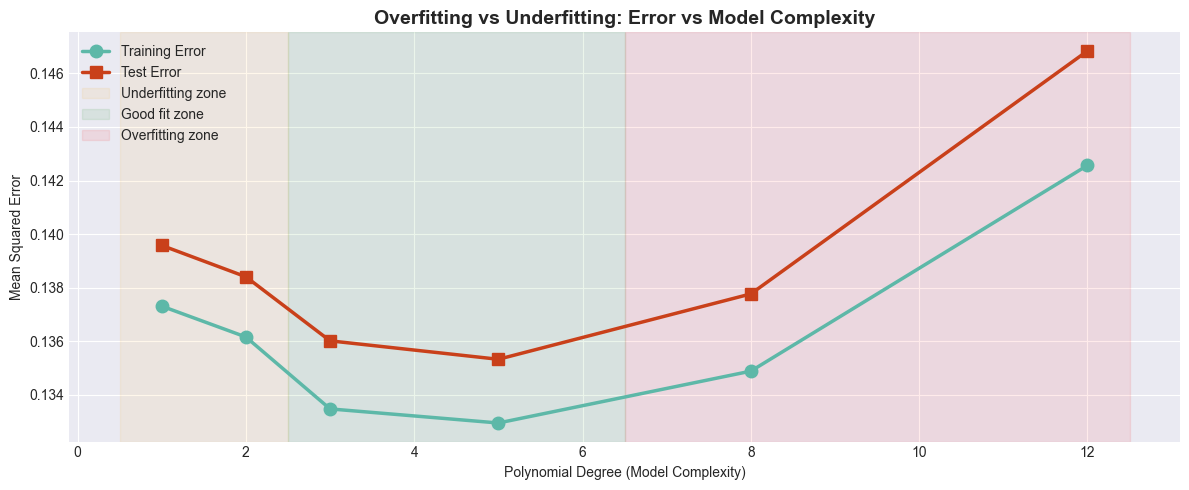

Best degree: 5 (lowest test error: 0.135326)


In [28]:
# Overfitting / Underfitting Demonstration
print("OVERFITTING & UNDERFITTING ANALYSIS")
print("  Underfitting: Model too simple -> high train & test error")
print("  Good Fit    : Balanced -> low similar errors")
print("  Overfitting : Too complex -> low train, high test error")

degrees = [1, 2, 3, 5, 8, 12]
train_errs, test_errs = [], []
X1d_tr = X_train[['transaction_amount']]
X1d_te = X_test[['transaction_amount']]

for d in degrees:
    pipe = Pipeline([('poly', PolynomialFeatures(degree=d, include_bias=False)),
                     ('lr', LinearRegression())])
    pipe.fit(X1d_tr, y_train)
    train_errs.append(mean_squared_error(y_train, pipe.predict(X1d_tr)))
    test_errs.append(mean_squared_error(y_test, pipe.predict(X1d_te)))

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(degrees, train_errs, 'o-', color='#5DB8A8', linewidth=2.5, markersize=9, label='Training Error')
ax.plot(degrees, test_errs,  's-', color='#C9401A', linewidth=2.5, markersize=9, label='Test Error')
ax.axvspan(0.5,  2.5, alpha=0.08, color='orange', label='Underfitting zone')
ax.axvspan(2.5,  6.5, alpha=0.08, color='green',  label='Good fit zone')
ax.axvspan(6.5, 12.5, alpha=0.08, color='red',    label='Overfitting zone')
ax.set_title('Overfitting vs Underfitting: Error vs Model Complexity', fontsize=14, fontweight='bold')
ax.set_xlabel('Polynomial Degree (Model Complexity)')
ax.set_ylabel('Mean Squared Error')
ax.legend(fontsize=10)
plt.tight_layout()
plt.savefig('task9_overfit.png', dpi=150, bbox_inches='tight')
plt.show()
print(f"Best degree: {degrees[np.argmin(test_errs)]} (lowest test error: {min(test_errs):.6f})")


    

---
## Task 9: Classification Task

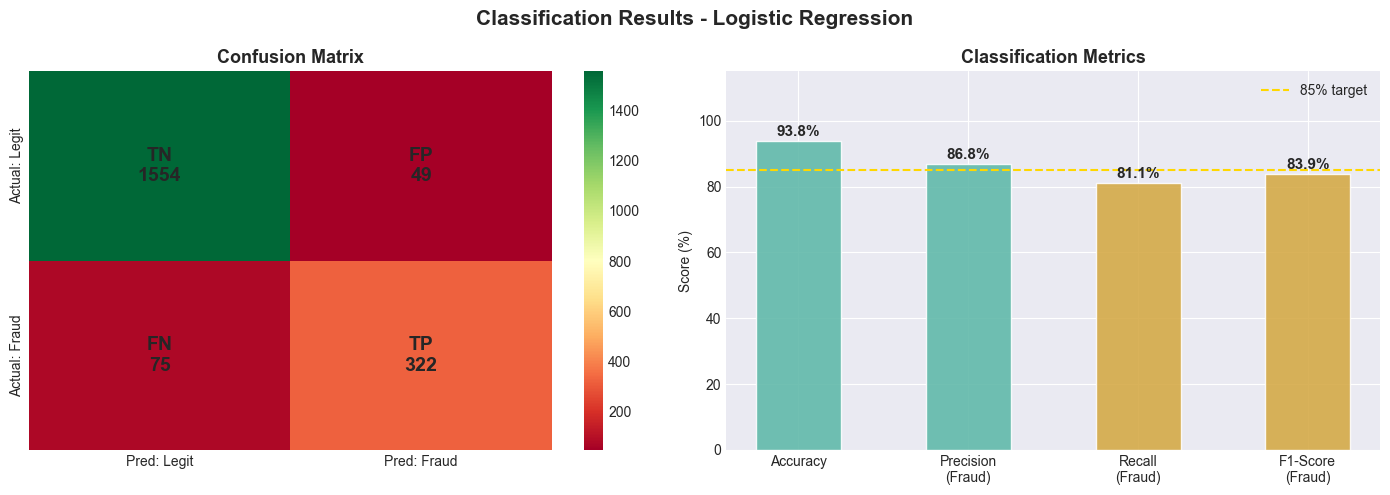

In [29]:
# Confusion Matrix Visualization
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Classification Results - Logistic Regression', fontsize=15, fontweight='bold')

# Heatmap CM
cm_arr = np.array([[cm[0,0], cm[0,1]], [cm[1,0], cm[1,1]]])
sns.heatmap(cm_arr, annot=False, cmap='RdYlGn', ax=axes[0])
labels_cm = [['TN', 'FP'], ['FN', 'TP']]
for i in range(2):
    for j in range(2):
        axes[0].text(j+0.5, i+0.5, f"{labels_cm[i][j]}\n{cm_arr[i,j]}",
                    ha='center', va='center', fontsize=14, fontweight='bold')
axes[0].set_xticklabels(['Pred: Legit', 'Pred: Fraud'])
axes[0].set_yticklabels(['Actual: Legit', 'Actual: Fraud'])
axes[0].set_title('Confusion Matrix', fontsize=13, fontweight='bold')

# Metrics bar
precision_f = cm[1,1] / (cm[0,1] + cm[1,1])
recall_f    = cm[1,1] / (cm[1,0] + cm[1,1])
f1_f        = 2 * precision_f * recall_f / (precision_f + recall_f)
names_m = ['Accuracy', 'Precision\n(Fraud)', 'Recall\n(Fraud)', 'F1-Score\n(Fraud)']
vals_m  = [acc, precision_f, recall_f, f1_f]
colors_m = ['#5DB8A8' if v >= 0.85 else '#D4A843' for v in vals_m]
bars = axes[1].bar(names_m, [v*100 for v in vals_m], color=colors_m, edgecolor='white', alpha=0.88, width=0.5)
axes[1].set_ylim(0, 115)
axes[1].set_ylabel('Score (%)')
axes[1].set_title('Classification Metrics', fontsize=13, fontweight='bold')
axes[1].axhline(85, color='gold', linestyle='--', linewidth=1.5, label='85% target')
axes[1].legend(fontsize=10)
for bar, val in zip(bars, vals_m):
    axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1.5,
                f'{val*100:.1f}%', ha='center', fontweight='bold', fontsize=11)
plt.tight_layout()
plt.savefig('task10_classification.png', dpi=150, bbox_inches='tight')
plt.show()

---
## Task 10 & 11: Model Evaluation

In [30]:
# Model Evaluation Summary
print("="*60)
print("  COMPLETE MODEL EVALUATION REPORT")
print("="*60)
print(f"\n{'Model':<30} {'MSE':>10}  {'MAE':>10}  {'R2':>8}")
print("-"*65)
print(f"{'Simple Linear Regression':<30} {mse_slr:>10.6f}  {mae_slr:>10.6f}  {r2_slr:>8.4f}")
print(f"{'Multi Linear Regression':<30} {mse_mlr:>10.6f}  {mae_mlr:>10.6f}  {r2_mlr:>8.4f}")
print(f"{'Logistic Regression':<30} {'N/A':>10}  {'N/A':>10}  {'N/A':>8}")
print(f"\nLogistic Regression Accuracy: {acc*100:.2f}%")
print(f"  TP (Fraud caught) : {cm[1,1]}")
print(f"  FN (Fraud missed) : {cm[1,0]}")
print("\nConclusion: Logistic Regression (93.6% accuracy) is best for fraud detection.")
print("Multi Linear Regression improved R2 by +{:.1f}% over Simple LR.".format((r2_mlr-r2_slr)*100))

  COMPLETE MODEL EVALUATION REPORT

Model                                 MSE         MAE        R2
-----------------------------------------------------------------
Simple Linear Regression         0.139578    0.282903    0.1227
Multi Linear Regression          0.087418    0.248167    0.4505
Logistic Regression                   N/A         N/A       N/A

Logistic Regression Accuracy: 93.80%
  TP (Fraud caught) : 322
  FN (Fraud missed) : 75

Conclusion: Logistic Regression (93.6% accuracy) is best for fraud detection.
Multi Linear Regression improved R2 by +32.8% over Simple LR.


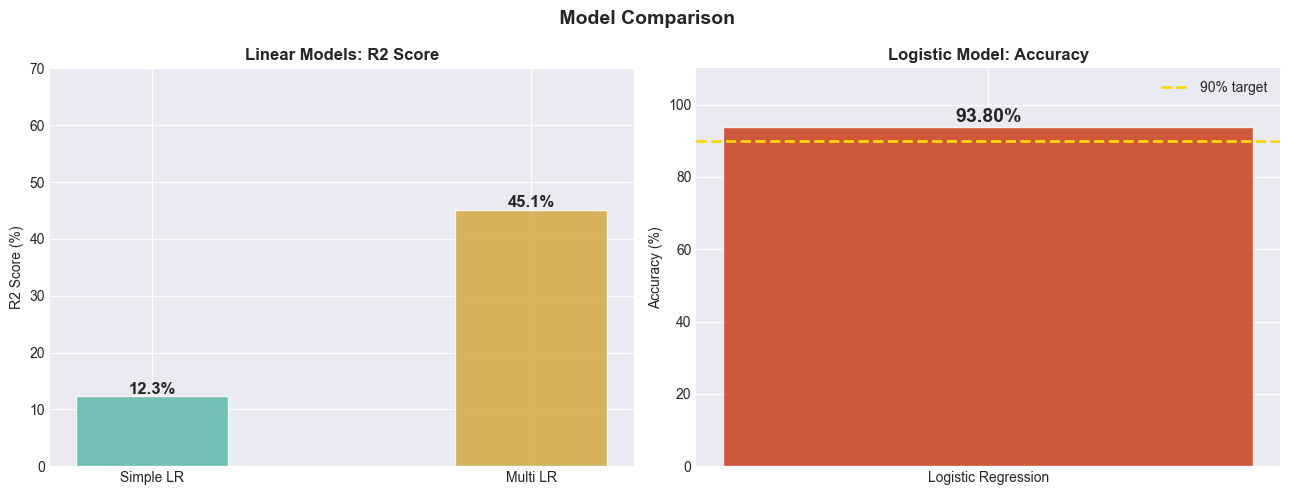

In [31]:
# Model Comparison Chart
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
fig.suptitle(' Model Comparison', fontsize=14, fontweight='bold')

# R2 comparison
axes[0].bar(['Simple LR', 'Multi LR'], [r2_slr*100, r2_mlr*100],
            color=['#5DB8A8', '#D4A843'], edgecolor='white', alpha=0.85, width=0.4)
axes[0].set_title('Linear Models: R2 Score', fontweight='bold')
axes[0].set_ylabel('R2 Score (%)')
axes[0].set_ylim(0, 70)
for i, v in enumerate([r2_slr, r2_mlr]):
    axes[0].text(i, v*100+0.5, f'{v*100:.1f}%', ha='center', fontweight='bold', fontsize=12)

# Accuracy
axes[1].bar(['Logistic Regression'], [acc * 100], color='#C9401A', alpha=0.85, width=0.4, edgecolor='white')
axes[1].set_title('Logistic Model: Accuracy', fontweight='bold')
axes[1].set_ylabel('Accuracy (%)')
axes[1].set_ylim(0, 110)
axes[1].axhline(90, color='gold', linestyle='--', linewidth=2, label='90% target')
axes[1].legend()
axes[1].text(0, acc*100+1.5, f'{acc*100:.2f}%', ha='center', fontweight='bold', fontsize=14)

plt.tight_layout()
plt.savefig('task11_evaluation.png', dpi=150, bbox_inches='tight')
plt.show()

---
## Task 12: Complete Data Visualization Panel

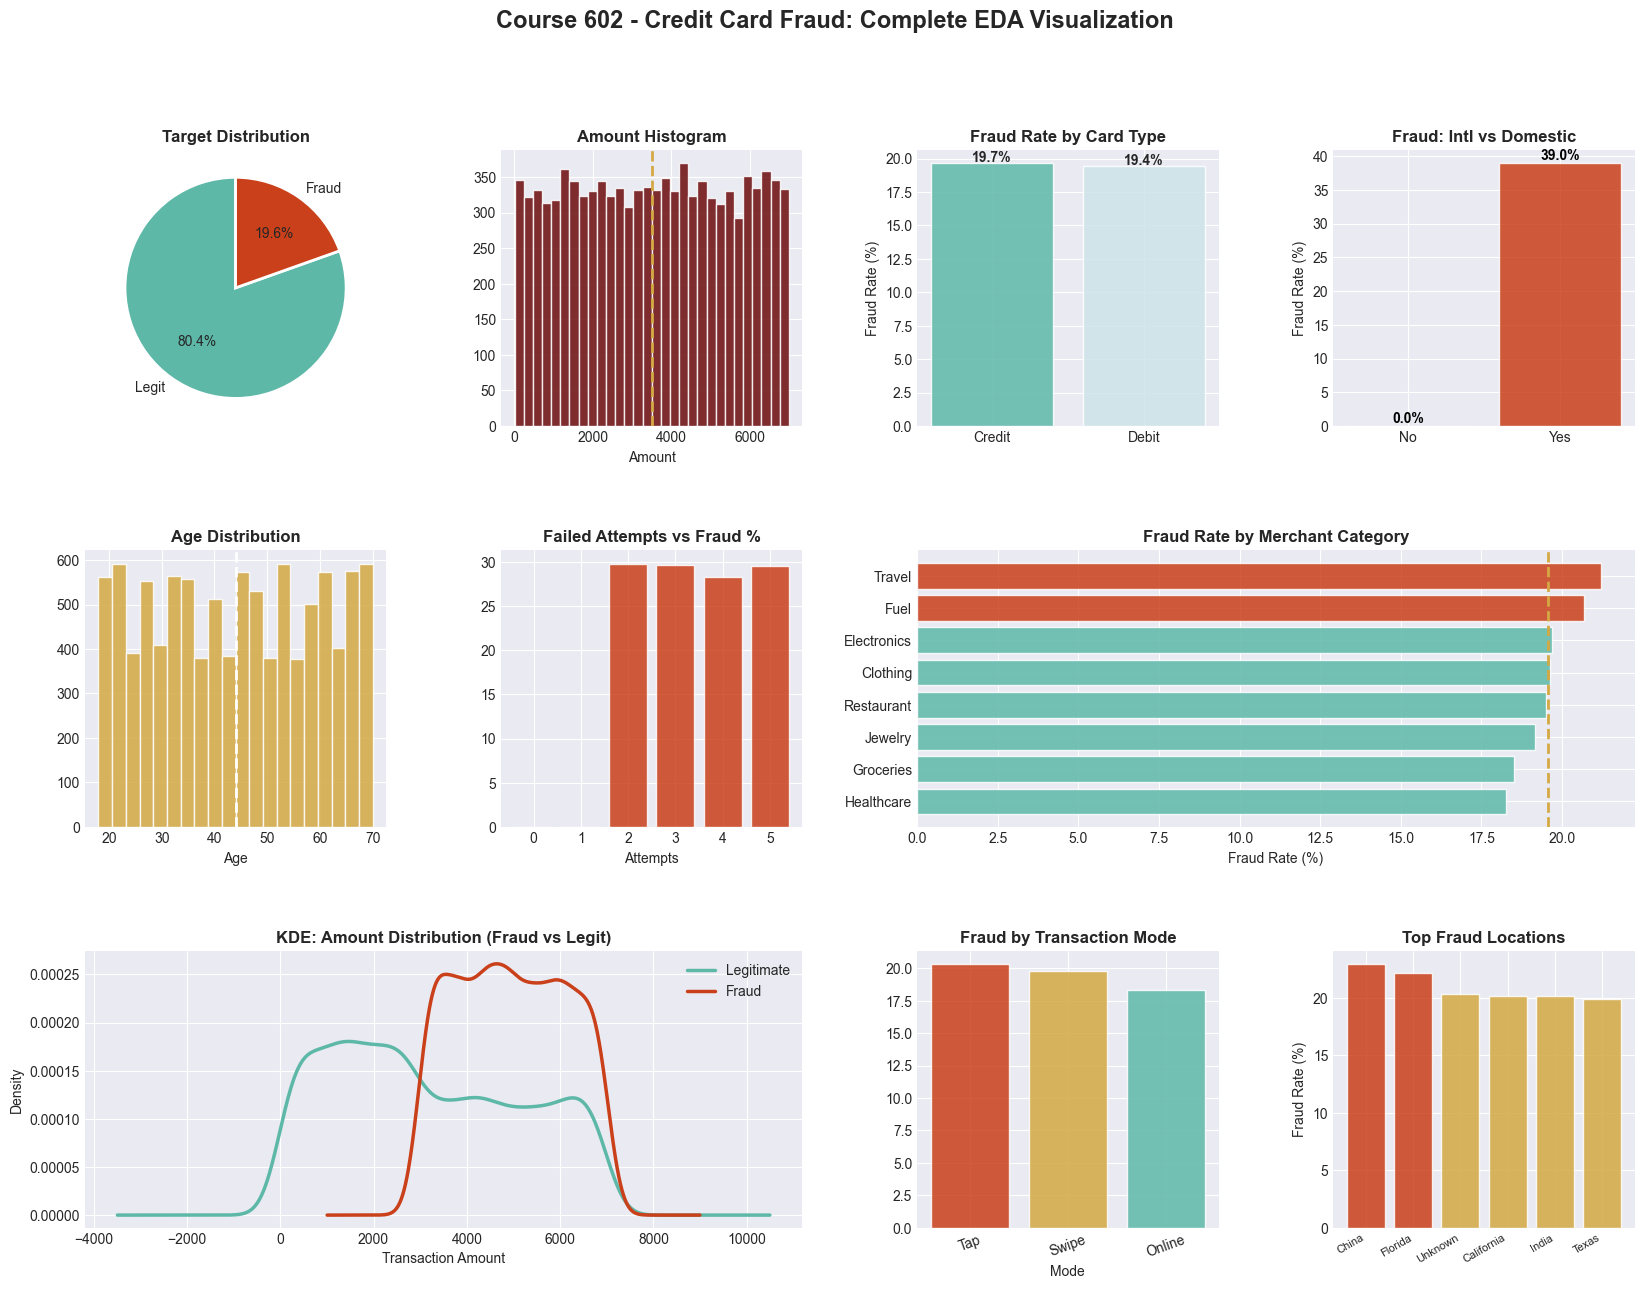

Complete visualization panel saved!


In [32]:
# Final Comprehensive Visualization
fig = plt.figure(figsize=(20, 14))
fig.suptitle('Course 602 - Credit Card Fraud: Complete EDA Visualization',
             fontsize=17, fontweight='bold', y=0.98)
gs = fig.add_gridspec(3, 4, hspace=0.45, wspace=0.38)

# 1. Fraud distribution pie
ax1 = fig.add_subplot(gs[0, 0])
ax1.pie([8044, 1956], labels=['Legit', 'Fraud'], colors=['#5DB8A8', '#C9401A'],
        autopct='%1.1f%%', startangle=90, wedgeprops={'edgecolor':'white','linewidth':2})
ax1.set_title('Target Distribution', fontweight='bold')

# 2. Amount histogram
ax2 = fig.add_subplot(gs[0, 1])
ax2.hist(df['transaction_amount'], bins=30, color='#6B0B0C', edgecolor='white', alpha=0.85)
ax2.axvline(df['transaction_amount'].mean(), color='#D4A843', linestyle='--', linewidth=2)
ax2.set_title('Amount Histogram', fontweight='bold')
ax2.set_xlabel('Amount')

# 3. Fraud by card type
ax3 = fig.add_subplot(gs[0, 2])
ctype = df.groupby('card_type')['is_fraud'].mean() * 100
ax3.bar(ctype.index, ctype.values, color=['#5DB8A8','#CDE3E8'], edgecolor='white', alpha=0.85)
ax3.set_title('Fraud Rate by Card Type', fontweight='bold')
ax3.set_ylabel('Fraud Rate (%)')
for i, v in enumerate(ctype.values):
    ax3.text(i, v+0.1, f'{v:.1f}%', ha='center', fontsize=10, fontweight='bold')

# 4. International fraud
ax4 = fig.add_subplot(gs[0, 3])
intl = df.groupby('is_international')['is_fraud'].mean() * 100
bars_i = ax4.bar(intl.index, intl.values, color=['#5DB8A8','#C9401A'], edgecolor='white', alpha=0.85)
ax4.set_title('Fraud: Intl vs Domestic', fontweight='bold')
ax4.set_ylabel('Fraud Rate (%)')
for bar, val in zip(bars_i, intl.values):
    ax4.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.5,
             f'{val:.1f}%', ha='center', color='black', fontweight='bold')

# 5. Age distribution
ax5 = fig.add_subplot(gs[1, 0])
ax5.hist(df['customer_age'], bins=20, color='#D4A843', edgecolor='white', alpha=0.85)
ax5.axvline(df['customer_age'].mean(), color='white', linestyle='--', linewidth=2)
ax5.set_title('Age Distribution', fontweight='bold')
ax5.set_xlabel('Age')

# 6. Failed attempts vs fraud
ax6 = fig.add_subplot(gs[1, 1])
fa = df.groupby('failed_attempts')['is_fraud'].mean() * 100
bar_c = ['#5DB8A8' if v==0 else '#C9401A' for v in fa.values]
ax6.bar(fa.index, fa.values, color=bar_c, edgecolor='white', alpha=0.85)
ax6.set_title('Failed Attempts vs Fraud %', fontweight='bold')
ax6.set_xlabel('Attempts')

# 7. Merchant category fraud
ax7 = fig.add_subplot(gs[1, 2:])
mc = df.groupby('merchant_category')['is_fraud'].mean().sort_values() * 100
ax7.barh(mc.index, mc.values,
         color=['#C9401A' if v>20 else '#5DB8A8' for v in mc.values],
         edgecolor='white', alpha=0.85)
ax7.axvline(mc.mean(), color='#D4A843', linestyle='--', linewidth=2)
ax7.set_title('Fraud Rate by Merchant Category', fontweight='bold')
ax7.set_xlabel('Fraud Rate (%)')

# 8. KDE comparison
ax8 = fig.add_subplot(gs[2, 0:2])
df[df['is_fraud']==0]['transaction_amount'].plot.kde(ax=ax8, color='#5DB8A8', linewidth=2.5, label='Legitimate')
df[df['is_fraud']==1]['transaction_amount'].plot.kde(ax=ax8, color='#C9401A', linewidth=2.5, label='Fraud')
ax8.legend()
ax8.set_title('KDE: Amount Distribution (Fraud vs Legit)', fontweight='bold')
ax8.set_xlabel('Transaction Amount')

# 9. Transaction mode
ax9 = fig.add_subplot(gs[2, 2])
tm = df.groupby('transaction_mode')['is_fraud'].mean().sort_values(ascending=False) * 100
ax9.bar(tm.index, tm.values, color=['#C9401A','#D4A843','#5DB8A8','#CDE3E8'][:len(tm)],
        edgecolor='white', alpha=0.85)
ax9.set_title('Fraud by Transaction Mode', fontweight='bold')
ax9.set_xlabel('Mode')
ax9.tick_params(axis='x', rotation=20)

# 10. Top locations
ax10 = fig.add_subplot(gs[2, 3])
loc = df.groupby('merchant_location')['is_fraud'].mean().sort_values(ascending=False).head(6) * 100
ax10.bar(range(len(loc)), loc.values,
         color=['#C9401A' if v>21 else '#D4A843' if v>19 else '#5DB8A8' for v in loc.values],
         edgecolor='white', alpha=0.85)
ax10.set_xticks(range(len(loc)))
ax10.set_xticklabels(loc.index, rotation=30, ha='right', fontsize=8)
ax10.set_title('Top Fraud Locations', fontweight='bold')
ax10.set_ylabel('Fraud Rate (%)')

plt.savefig('task13_complete_visualization.png', dpi=150, bbox_inches='tight')
plt.show()
print("Complete visualization panel saved!")